# Thí nghiệm cấu hình A — MLP với lịch sử lưu lượng

So sánh A của V2 với A + lịch sử, giữ bộ MLP đã thắng V2. Cả hai đọc `data/processed/train.csv` và `validation.csv`.

Ba cột thêm là `lag_24h`, `lag_168h` và `mean_24h`. Trung bình 24 giờ chỉ dùng các giờ trước giờ dự đoán và cần ít nhất 18 quan sát. Kịch bản dự đoán theo từng giờ giả định lưu lượng thực tế của các giờ đã qua có sẵn, kể cả các giờ trước đó trong validation.

A và A + lịch sử dùng cùng các giờ đủ cả ba cột trong từng lần fit và chấm. MAE V2 **232,022** là mốc đã lưu trên toàn bộ 6.086 giờ validation. Để đo ảnh hưởng của lịch sử, dùng cặp kết quả trên cùng các giờ trong notebook này.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## Params

In [1]:
MODEL_PARAMS = {
    "MLP": {
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.001,
        "learning_rate_init": 0.001,
        "batch_size": 256,
        "max_iter": 500,
        "early_stopping": False,
        "random_state": 42,
    },
}

CV_SPLITS = 3
CALENDAR_COLUMNS = ["hour", "day_of_week", "month"]
BINARY_COLUMNS = ["is_weekend", "is_holiday"]
TARGET_COLUMN = "traffic_volume"
CLIP_NEGATIVE_PREDICTIONS = True
HOURS_TO_PLOT = 72

## Đọc dữ liệu và tạo đặc trưng lịch sử

In [2]:
from datetime import datetime
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cwd = Path.cwd()
project_dir = next(
    (
        candidate
        for parent in (cwd, *cwd.parents)
        for candidate in (parent, parent / "metro_interstate_traffic_volume")
        if (candidate / "data" / "processed" / "train.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy data/processed/train.csv.")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.features import HISTORY_FEATURES, add_history_features

processed_dir = project_dir / "data" / "processed"
import sys
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
from src.experiment_data import load_experiment_splits

data_splits = load_experiment_splits(project_dir=project_dir)
train, validation = data_splits["train"], data_splits["validation"]

assert train.columns.equals(validation.columns)
for part in (train, validation):
    assert part["date_time"].is_unique
    assert part["date_time"].is_monotonic_increasing
assert train["date_time"].max() < validation["date_time"].min()

holiday_columns = [column for column in train.columns if column.startswith("holiday_")]
binary_columns = BINARY_COLUMNS + holiday_columns
features_A = CALENDAR_COLUMNS + binary_columns

history_table = add_history_features(
    pd.concat([train, validation], ignore_index=True)
)
train = history_table.iloc[:len(train)].copy()
validation = history_table.iloc[len(train):].copy()

CONFIG_FEATURES = {
    "A": features_A,
    "A + lịch sử": [*features_A, *HISTORY_FEATURES],
}

display(pd.DataFrame([
    {
        "Tập": name,
        "Tổng số giờ": len(part),
        "Số giờ đủ lịch sử": part[HISTORY_FEATURES].notna().all(axis=1).sum(),
    }
    for name, part in (("Train", train), ("Validation", validation))
]))

,Tập,Tổng số giờ,Số giờ đủ lịch sử
0,Train,28402,22503
1,Validation,6086,6050


## So sánh trên 3 fold theo thời gian

Tạo ranh giới các fold trên train theo cách V2 dùng. Sau đó giữ những giờ đủ lịch sử trong phần học và phần chấm của mỗi fold, dùng cùng các dòng cho hai mô hình. Tổng cộng có 6 lần fit trong CV.

In [3]:
def fit_mlp(frame, config):
    columns = CONFIG_FEATURES[config]
    transformers = [
        ("calendar", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CALENDAR_COLUMNS),
        ("binary", "passthrough", binary_columns),
    ]
    if config == "A + lịch sử":
        transformers.append(("history", StandardScaler(), HISTORY_FEATURES))

    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer(transformers)),
        ("model", TransformedTargetRegressor(
            regressor=MLPRegressor(**MODEL_PARAMS["MLP"]),
            transformer=StandardScaler(),
        )),
    ])
    return pipeline.fit(frame[columns], frame[TARGET_COLUMN])


def predict_volume(model, frame, config):
    prediction = model.predict(frame[CONFIG_FEATURES[config]])
    if CLIP_NEGATIVE_PREDICTIONS:
        prediction = prediction.clip(min=0)
    return prediction


def keep_history(frame):
    return frame.dropna(subset=HISTORY_FEATURES)


cv_rows = []
for fold, (train_idx, score_idx) in enumerate(TimeSeriesSplit(n_splits=CV_SPLITS).split(train), start=1):
    fit = keep_history(train.iloc[train_idx])
    score = keep_history(train.iloc[score_idx])
    for config in CONFIG_FEATURES:
        print(f"Fold {fold}/{CV_SPLITS} · {config}", flush=True)
        model = fit_mlp(fit, config)
        prediction = predict_volume(model, score, config)
        cv_rows.append({
            "Cấu hình": config,
            "Fold": fold,
            "Giờ train": len(fit),
            "Giờ chấm": len(score),
            "Train đến": fit["date_time"].max(),
            "Chấm từ": score["date_time"].min(),
            "Chấm đến": score["date_time"].max(),
            "MAE": mean_absolute_error(score[TARGET_COLUMN], prediction),
        })

cv_table = pd.DataFrame(cv_rows)
cv_summary = cv_table.groupby("Cấu hình", sort=False)["MAE"].mean().rename("MAE CV").reset_index()
display(cv_table.round(3))
display(cv_summary.round(3))

Fold 1/3 · A
Fold 1/3 · A + lịch sử
Fold 2/3 · A
Fold 2/3 · A + lịch sử
Fold 3/3 · A
Fold 3/3 · A + lịch sử


,Cấu hình,Fold,Giờ train,Giờ chấm,Train đến,Chấm từ,Chấm đến,MAE
0,A,1,5841,5302,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,281.002
1,A + lịch sử,1,5841,5302,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,247.266
2,A,2,11143,4441,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,281.109
3,A + lịch sử,2,11143,4441,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,245.850
4,A,3,15584,6919,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,327.068
5,A + lịch sử,3,15584,6919,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,254.676


,Cấu hình,MAE CV
0,A,296.393
1,A + lịch sử,249.264


## Đánh giá trên validation và lưu Excel

Fit lại cả hai mô hình trên cùng tập train đủ lịch sử. Chấm cả hai trên cùng các giờ validation đủ lịch sử. Mỗi lần chạy tạo một file Excel, ghi tham số, MAE, RMSE, R² và điểm từng fold.

In [4]:
fit = keep_history(train)
score = keep_history(validation)
prediction_table = score[["date_time", TARGET_COLUMN]].copy()
rows = []
for config in CONFIG_FEATURES:
    print(f"Validation · {config}", flush=True)
    model = fit_mlp(fit, config)
    prediction = predict_volume(model, score, config)
    prediction_table[config] = prediction
    rows.append({
        "Cấu hình": config,
        "Số đặc trưng": len(CONFIG_FEATURES[config]),
        "Giờ train": len(fit),
        "Giờ validation": len(score),
        "MAE": mean_absolute_error(score[TARGET_COLUMN], prediction),
        "RMSE": mean_squared_error(score[TARGET_COLUMN], prediction) ** 0.5,
        "R2": r2_score(score[TARGET_COLUMN], prediction),
        "n_iter": model.named_steps["model"].regressor_.n_iter_,
    })

params = {**MODEL_PARAMS["MLP"], "hidden_layer_sizes": str(MODEL_PARAMS["MLP"]["hidden_layer_sizes"])}
results = pd.DataFrame(rows).merge(cv_summary, on="Cấu hình", validate="one_to_one").assign(**params)
results["Chênh MAE so với A"] = results["MAE"] - results.loc[results["Cấu hình"].eq("A"), "MAE"].iloc[0]
display(results.round({"MAE": 3, "RMSE": 3, "R2": 4, "MAE CV": 3}))

run_id = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S_%f")
experiment_dir = project_dir / "experiments" / "18-11-2026_ConfigA_HistoryMLP_Phuc"
excel_path = experiment_dir / f"ConfigA_MLP_History_{run_id}.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Kết quả", index=False)
    cv_table.to_excel(writer, sheet_name="CV từng fold", index=False)
print(f"Đã lưu Excel tại {excel_path}")

Validation · A
Validation · A + lịch sử


,Cấu hình,Số đặc trưng,Giờ train,Giờ validation,MAE,RMSE,R2,n_iter,MAE CV,hidden_layer_sizes,activation,solver,alpha,learning_rate_init,batch_size,max_iter,early_stopping,random_state,Chênh MAE so với A
0,A,17,22503,6050,260.068,385.645,0.9615,30,296.393,"(64, 32)",relu,adam,0.001,0.001,256,500,False,42,0.000000
1,A + lịch sử,20,22503,6050,194.780,302.769,0.9762,57,249.264,"(64, 32)",relu,adam,0.001,0.001,256,500,False,42,-65.287479


Đã lưu Excel tại d:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\18-11-2026_ConfigA_HistoryMLP_Phuc\ConfigA_MLP_History_20261118_090434_773047.xlsx


## Vẽ và lưu biểu đồ dự đoán

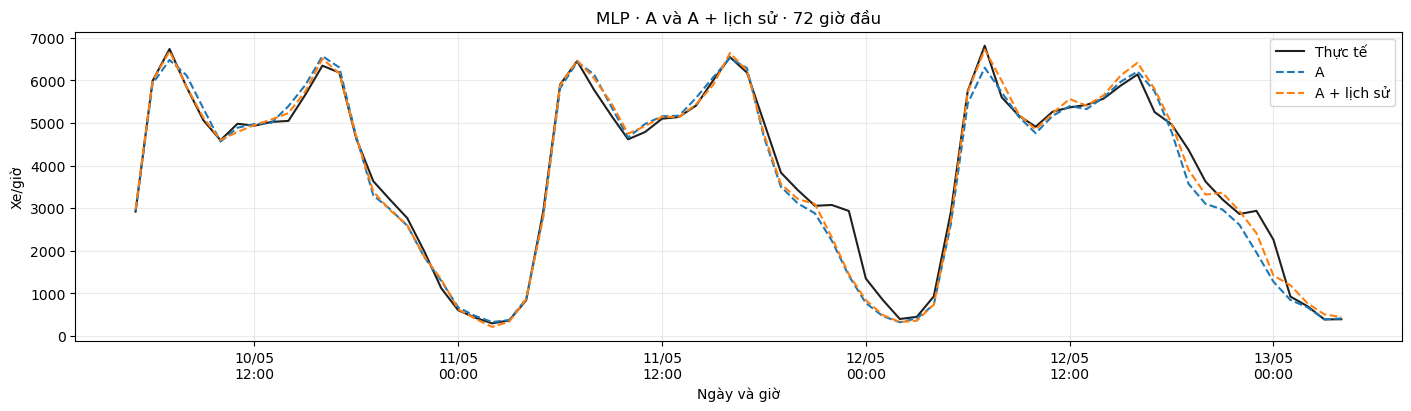

In [5]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plot_index = pd.date_range(
    start=prediction_table["date_time"].min(),
    periods=HOURS_TO_PLOT,
    freq="h",
)
# Giữ NaN ở các giờ thiếu để biểu đồ ngắt tại khoảng trống.
plot_data = prediction_table.set_index("date_time").reindex(plot_index)

fig, ax = plt.subplots(figsize=(14, 4), layout="constrained")
ax.plot(plot_data.index, plot_data[TARGET_COLUMN], color="#202020", label="Thực tế")
for config in CONFIG_FEATURES:
    ax.plot(plot_data.index, plot_data[config], linestyle="--", label=config)
ax.set_title("MLP · A và A + lịch sử · 72 giờ đầu")
ax.set_ylabel("Xe/giờ")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.set_xlabel("Ngày và giờ")

output_dir = experiment_dir / "img"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"config_a_mlp_history_{HOURS_TO_PLOT}h_{run_id}.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

## Nhận xét sau khi chạy

Lần chạy `20261118_090434_773047` giữ bộ tham số MLP thắng ở V2. Hai phương án cùng học trên **22.503 giờ train** và cùng chấm trên **6.050 giờ validation** đủ lịch sử. MAE và RMSE tính theo xe/giờ.

| Phương án | MAE fold 1 | MAE fold 2 | MAE fold 3 | MAE CV | MAE validation | RMSE validation | R² validation |
|---|---:|---:|---:|---:|---:|---:|---:|
| A | 281,00 | 281,11 | 327,07 | 296,39 | 260,07 | 385,65 | 0,9615 |
| A + lịch sử | **247,27** | **245,85** | **254,68** | **249,26** | **194,78** | **302,77** | **0,9762** |

Thêm lịch sử giảm MAE ở cả ba fold. Mức giảm lớn nhất là **72,39 xe/giờ** ở fold 3. Trên validation, MAE giảm **65,29 xe/giờ (25,1%)**, RMSE giảm **82,88 xe/giờ** và R² tăng từ **0,9615** lên **0,9762**. Đối chứng trực tiếp của lượt này là A đạt **260,07** trên cùng các giờ đủ lịch sử. Mốc A của V2 là **232,02** trên toàn bộ 6.086 giờ validation, với 28.402 giờ huấn luyện.

Cách lọc giờ đủ lịch sử giống thí nghiệm B/C của Huy ngày 17/11. Cả hai dùng `lag_24h`, `lag_168h` và `mean_24h`, với trung bình 24 giờ cần ít nhất 18 quan sát trước giờ dự đoán. Notebook này đọc CSV trong `data/processed`, thêm lịch sử vào A và đánh giá MLP qua 3 fold theo thời gian. Huy đọc CSV gốc, thêm lịch sử vào B để tạo C và đối chứng Random Forest, Gradient Boosting trên validation.

Kết quả áp dụng cho dự đoán từng giờ khi lưu lượng thực tế ở các giờ đã qua có sẵn.